# Información y entropía: sorpresa de un símbolo y promedio de una fuente

**Tema 2 · Apartados 2.1–2.2 · Demostración orientativa: 10–20 minutos.**

Distinguir información individual, contribución a la entropía y promedio observado en una secuencia finita.

## Cómo experimentar

Ejecuta todo de arriba abajo. Cambia un parámetro, predice qué ocurrirá y vuelve a ejecutar todas las celdas.
En Colab: *Entorno de ejecución → Ejecutar todas*. En Jupyter: *Kernel → Restart Kernel and Run All Cells*.
Los comentarios `#@param` permiten formularios en Colab; en Jupyter puedes editar los valores.

En la web, «Abrir en Colab» abre este cuaderno directamente en el navegador.
«Descargar cuaderno .ipynb» permite guardarlo y abrirlo en Jupyter o importarlo en Colab.
Puedes guardar una copia en tu Google Drive o descargar tu cuaderno desde Colab para conservar cambios.
Los cambios en tu sesión no modifican los originales de este repositorio.
La vista HTML muestra los resultados guardados; no recalcula las gráficas.
Los datos se generan en el propio cuaderno. No se instalan paquetes ni se descargan datos.
Solo se necesitan NumPy, Matplotlib y la biblioteca estándar de Python; IPython muestra las tablas.

## Modelo y pregunta

Una fuente sin memoria genera símbolos independientes con probabilidades fijas $p_i$.
La información de un símbolo es $I(a_i)=-\log_2 p_i$; la entropía es su promedio:
$$H(X)=\sum_i p_i I(a_i).$$
Un símbolo raro puede aportar mucha información cuando aparece, pero su contribución $p_i I(a_i)$
al promedio puede ser pequeña. Una distribución de probabilidad cero no genera observaciones;
su contribución a $H$ es cero, aunque $-\log_2 0$ no sea finito.

Introducimos **pesos no negativos** y los normalizamos para obtener probabilidades. La primera
figura y la secuencia simulada usan esos pesos. La segunda figura es otro experimento:
una fuente binaria con $P(0)=p_0$, cuya entropía es $H_b(p_0)$.
$p_0$ solo afecta a esa segunda figura.

En una realización finita comparamos la información media calculada con el **modelo conocido**
y la entropía calculada a partir de las **frecuencias observadas**. Son cantidades distintas.
El límite de compresión se refiere a una longitud media de código, no a que todas las secuencias
deban ocupar exactamente $nH(X)$ bits.

In [1]:
import math
import html
import itertools
import heapq
from fractions import Fraction
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, HTML
plt.rcParams.update({'font.size': 11, 'axes.spines.top': False,
                     'axes.spines.right': False})
AZUL = '#006d75'
NARANJA = '#b95028'
GRIS = '#617583'

def tabla(cabeceras, filas):
    def celda(x):
        return html.escape(str(x))
    cuerpo = ''.join('<tr>' + ''.join('<td>' + celda(x) + '</td>' for x in fila)
                     + '</tr>' for fila in filas)
    display(HTML('<div style="overflow-x:auto"><table><thead><tr>'
                 + ''.join('<th>' + celda(x) + '</th>' for x in cabeceras)
                 + '</tr></thead><tbody>' + cuerpo + '</tbody></table></div>'))

def entropia(prob):
    p = np.asarray(prob, dtype=float)
    p = p[p > 0]
    return float(-np.sum(p * np.log2(p)))

## Parámetros

Cambia un valor cada vez. Los rangos y las unidades aparecen en los comentarios.

In [2]:
#@title Parámetros
pesos = "0.5, 0.25, 0.25" #@param {type:"string"}
p_0 = 0.9 #@param {type:"slider", min:0, max:1, step:0.01}
n_muestras = 2000 #@param {type:"integer"}
semilla = 2026 #@param {type:"integer"}
w = np.array([float(x.strip()) for x in pesos.split(',')])
assert 2 <= len(w) <= 8 and np.all(np.isfinite(w))
assert np.all(w >= 0) and w.sum() > 0, 'Los pesos no pueden ser todos cero.'
assert 0 <= p_0 <= 1
assert isinstance(n_muestras, int) and 50 <= n_muestras <= 50000
assert isinstance(semilla, int) and 0 <= semilla <= 999999
p = w / w.sum()
simbolos = [f'a{i+1}' for i in range(len(p))]

## 1. Mucha sorpresa no significa mucha contribución al promedio

El panel izquierdo muestra $I(a_i)$ para los símbolos de probabilidad positiva.
El derecho muestra $p_i I(a_i)$: la suma de sus barras es la entropía.
Las contribuciones nulas se representan como cero; la información de un símbolo imposible
se indica en la tabla, sin dibujar una barra infinita.

Símbolo,Probabilidad,Información (bits),Contribución (bits/símbolo)
a1,0.5000,1.0000,0.5000
a2,0.2500,2.0000,0.5000
a3,0.2500,2.0000,0.5000


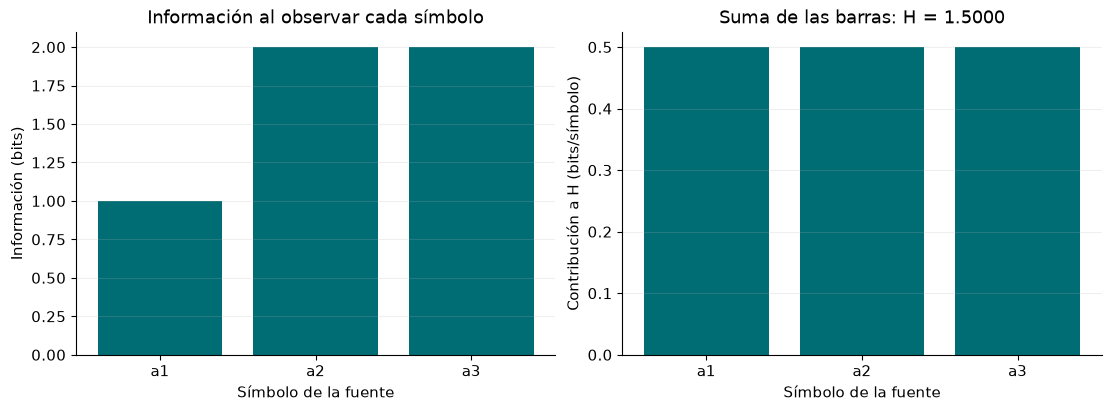

H(X) = 1.500000 bits/símbolo; máximo con 3 símbolos: 1.584963.


In [3]:
info = np.full(len(p), np.inf)
posibles = p > 0
info[posibles] = -np.log2(p[posibles])
contrib = np.zeros(len(p))
contrib[posibles] = p[posibles] * info[posibles]
H = entropia(p)
tabla(['Símbolo', 'Probabilidad', 'Información (bits)', 'Contribución (bits/símbolo)'],
      [(s, f'{pi:.4f}', f'{ii:.4f}' if pi > 0 else 'Imposible: +∞', f'{ci:.4f}')
       for s, pi, ii, ci in zip(simbolos, p, info, contrib)])
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout='constrained')
xs = np.arange(len(p))
axes[0].bar(xs[posibles], info[posibles], color=AZUL)
axes[0].set(ylabel='Información (bits)', title='Información al observar cada símbolo')
axes[1].bar(xs, contrib, color=AZUL)
axes[1].set(ylabel='Contribución a H (bits/símbolo)', title=f'Suma de las barras: H = {H:.4f}')
for ax in axes:
    ax.set_xticks(xs, simbolos)
    ax.set_xlabel('Símbolo de la fuente')
    ax.grid(axis='y', alpha=.2)
plt.show()
print(f'H(X) = {H:.6f} bits/símbolo; máximo con {len(p)} símbolos: {np.log2(len(p)):.6f}.')

## 2. Entropía binaria y promedio de una realización

El máximo de la curva binaria está en $p_0=1/2$, no cuando un símbolo es muy raro.
En el segundo panel, cada punto usa el prefijo de longitud $m$ de **una misma realización**
de la fuente definida por los pesos. El promedio conocido es
$m^{-1}\sum_{t=1}^{m}[-\log_2 p(x_t)]$.
La entropía empírica usa las frecuencias de ese prefijo.
Ninguna curva finita tiene por qué ser monótona ni coincidir exactamente con $H(X)$.

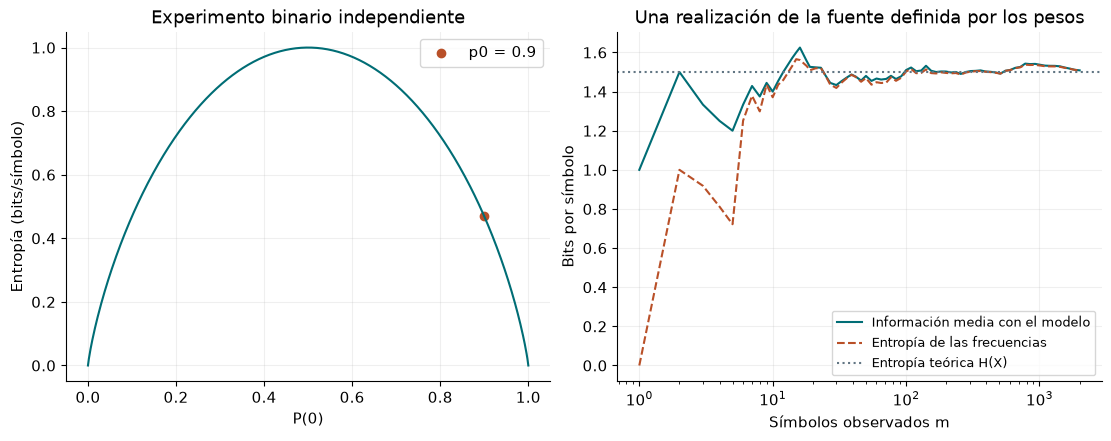

Información media observada: 1.508500; entropía empírica: 1.508274.
Información de la secuencia: 3017.000 bits; nH(X) = 3000.000 bits.


In [4]:
muestra = np.random.default_rng(semilla).choice(len(p), n_muestras, p=p)
acumulada = np.cumsum(info[muestra])
ms = np.unique(np.geomspace(1, n_muestras, 90).astype(int))
H_emp = np.array([entropia(np.bincount(muestra[:m], minlength=len(p))/m) for m in ms])
media_info = acumulada[ms-1] / ms
ps = np.linspace(0, 1, 501)
Hb = np.array([entropia([q, 1-q]) for q in ps])
H_punto = entropia([p_0, 1-p_0])
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3), layout='constrained')
axes[0].plot(ps, Hb, color=AZUL)
axes[0].scatter([p_0], [H_punto], c=NARANJA, label=f'p0 = {p_0:g}')
axes[0].set(xlabel='P(0)', ylabel='Entropía (bits/símbolo)', title='Experimento binario independiente')
axes[0].legend()
axes[1].plot(ms, media_info, c=AZUL, label='Información media con el modelo')
axes[1].plot(ms, H_emp, c=NARANJA, ls='--', label='Entropía de las frecuencias')
axes[1].axhline(H, c=GRIS, ls=':', label='Entropía teórica H(X)')
axes[1].set(xscale='log', xlabel='Símbolos observados m', ylabel='Bits por símbolo',
            title='Una realización de la fuente definida por los pesos')
axes[1].legend(fontsize=9)
for ax in axes: ax.grid(alpha=.2)
plt.show()
print(f'Información media observada: {media_info[-1]:.6f}; entropía empírica: {H_emp[-1]:.6f}.')
print(f'Información de la secuencia: {acumulada[-1]:.3f} bits; nH(X) = {n_muestras*H:.3f} bits.')

## Antes de mirar la explicación

1. Cambia los pesos a `0.98, 0.01, 0.01`. ¿Qué símbolos aportan más información? ¿Quién domina el promedio?
2. Pon pesos iguales. ¿Por qué todas las barras de información coinciden?
3. Prueba `1, 0, 0` y después cambia la semilla. ¿Puede aparecer un símbolo imposible?
4. Compara `p_0=0.1`, `0.5` y `0.9`. ¿Por qué los extremos simétricos tienen la misma entropía?
5. Reduce la longitud de la muestra. ¿Las dos estimaciones de la segunda figura siguen siendo iguales?

## Explicación de lo observado

1. Los raros aportan $-\log_2(0.01)\simeq6.644$ bits cuando aparecen. Cada uno contribuye
   unos 0.0664 bits al promedio; el frecuente contribuye unos 0.0286. La entropía es unos 0.1614,
   aunque algunas observaciones aporten más de seis bits.
2. Con tres símbolos equiprobables, $I(a_i)=H(X)=\log_2 3\simeq1.585$.
   Una palabra de código individual debe tener longitud entera: entropía y longitud no son sinónimos.
3. No. La fuente es determinista y su entropía es cero. Cambiar la semilla no modifica su salida.
4. Intercambiar las etiquetas 0 y 1 no cambia la incertidumbre. En 0.5 se alcanza un bit por símbolo;
   en 0.1 y 0.9 se obtiene aproximadamente 0.469.
5. La información media evalúa lo observado con el modelo fijo; la entropía empírica cambia también
   el modelo al sustituir probabilidades por frecuencias. Ambas fluctúan con una muestra finita.

## Comprobación del modelo

Contrastamos casos conocidos y la relación entre probabilidad e información.

In [5]:
assert np.isclose(H, contrib.sum())
assert 0 <= H <= np.log2(len(p)) + 1e-12
assert np.isclose(entropia([.5, .25, .25]), 1.5)
assert entropia([1, 0, 0]) == 0
assert np.isclose(entropia([.1, .9]), entropia([.9, .1]))
assert np.all(p[muestra] > 0)
assert np.isclose(acumulada[-1], np.dot(np.bincount(muestra, minlength=len(p))[posibles], info[posibles]))
print('Probabilidades, entropías límite e información de la secuencia comprobadas.')

Probabilidades, entropías límite e información de la secuencia comprobadas.


## Referencias

Ejemplo y código propios para TDI.

- TDI, tema 2, apartados 2.1–2.2: «Fuentes sin memoria», «Información asociada a un mensaje» y «Entropía y límite de compresión».

Los supuestos y las convenciones de este experimento se explican en «Modelo y pregunta».